In [9]:
import pandas as pd
import matplotlib.pyplot as plt         #importing
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

In [10]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn (1).csv")
                                                            #data loading and understanding
display(df.head())
print("Shape:", df.shape)
print(df.dtypes)
display(df.describe())
print(df["Churn"].value_counts())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Shape: (7043, 21)
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [11]:
print(df.isnull().sum())

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")                          #data preprocessing
print("Blank TotalCharges:", df["TotalCharges"].isnull().sum())
display(df[df["TotalCharges"].isnull()][["tenure", "TotalCharges"]])

df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Duplicate rows:", df.duplicated().sum())

df = df.drop("customerID", axis=1)
print("Shape after cleaning:", df.shape)

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Blank TotalCharges: 11


,tenure,TotalCharges
488,0,NaN
753,0,NaN
936,0,NaN
1082,0,NaN
1340,0,NaN
3331,0,NaN
3826,0,NaN
4380,0,NaN
5218,0,NaN
6670,0,NaN


Duplicate rows: 0
Shape after cleaning: (7043, 20)


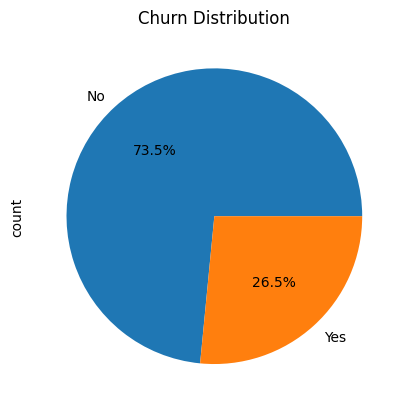

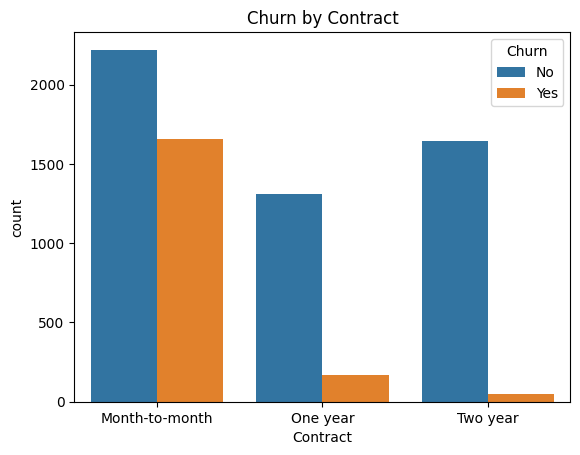

Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


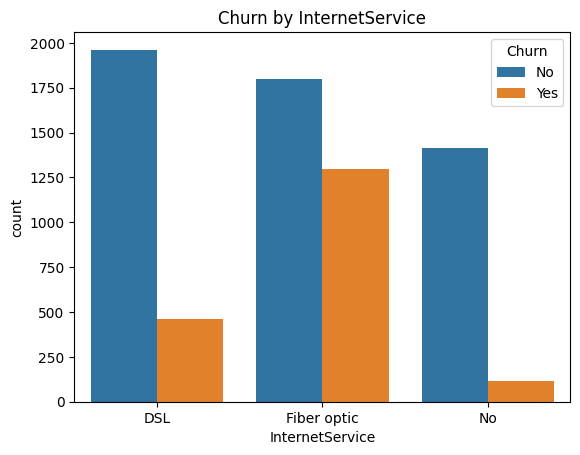

Churn,No,Yes
InternetService,,
DSL,81.0,19.0
Fiber optic,58.1,41.9
No,92.6,7.4


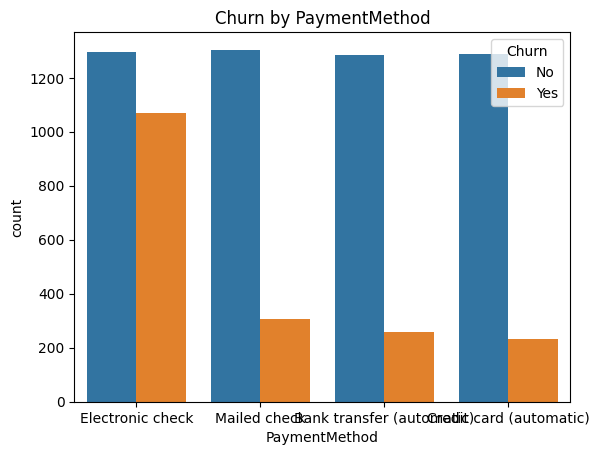

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.3,16.7
Credit card (automatic),84.8,15.2
Electronic check,54.7,45.3
Mailed check,80.9,19.1


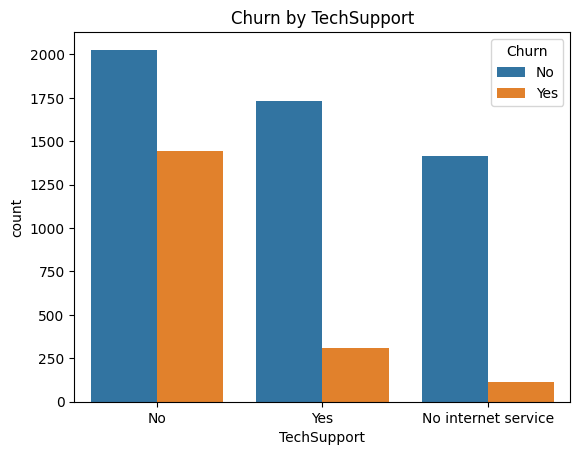

Churn,No,Yes
TechSupport,,
No,58.4,41.6
No internet service,92.6,7.4
Yes,84.8,15.2


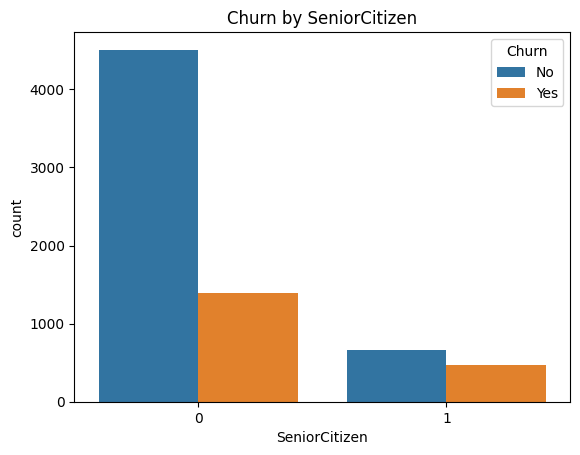

Churn,No,Yes
SeniorCitizen,,
0,76.4,23.6
1,58.3,41.7


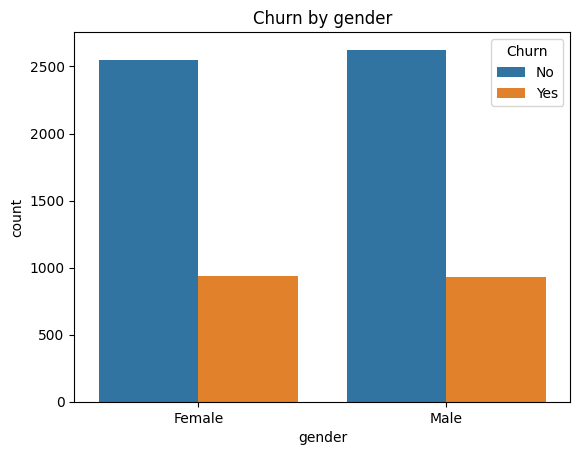

Churn,No,Yes
gender,,
Female,73.1,26.9
Male,73.8,26.2


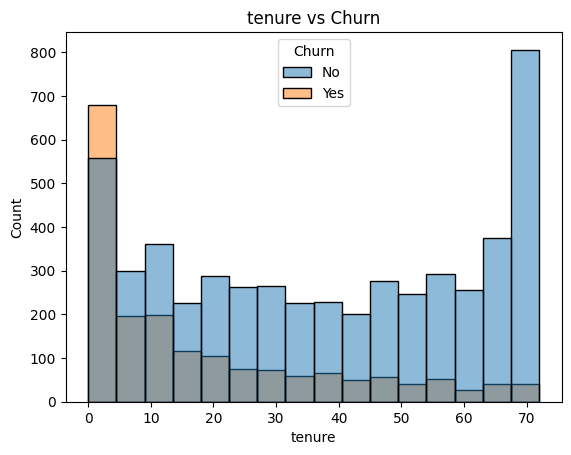

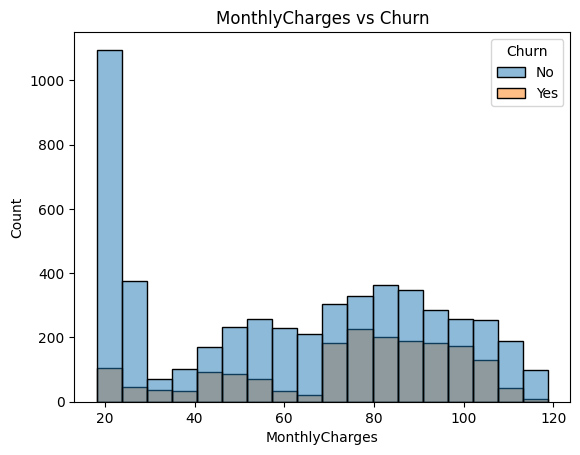

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.569965,61.265124,2549.911442
Yes,17.979133,74.441332,1531.796094


In [12]:
df["Churn"].value_counts().plot.pie(autopct="%1.1f%%")
plt.title("Churn Distribution")                                                               #exploratory data analysis
plt.show()

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen", "gender"]:
    sns.countplot(x=col, hue="Churn", data=df)
    plt.title("Churn by " + col)
    plt.show()
    display(pd.crosstab(df[col], df["Churn"], normalize="index").round(3) * 100)

for col in ["tenure", "MonthlyCharges"]:
    sns.histplot(data=df, x=col, hue="Churn")
    plt.title(col + " vs Churn")
    plt.show()

display(df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean())

In [13]:
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
                                                                                       #feature engineering and encoding
def make_features(data):
    data = data.replace({"No internet service": "No", "No phone service": "No"})
    data["num_services"] = (data[services] == "Yes").sum(axis=1)
    data = pd.get_dummies(data, drop_first=True, dtype=int)
    return data

X = make_features(df.drop("Churn", axis=1))
y = df["Churn"].map({"Yes": 1, "No": 0})

print("X shape:", X.shape)
print("y shape:", y.shape)
display(X.head())

X shape: (7043, 24)
y shape: (7043,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,num_services,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_Yes,...,DeviceProtection_Yes,TechSupport_Yes,StreamingTV_Yes,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,1,0,1,0,0,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,3,1,0,0,1,0,...,1,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,3,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,3,1,0,0,0,0,...,1,1,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
                                                                                                          #training and testing
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

lr = LogisticRegression(max_iter=1000, class_weight="balanced")
lr.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42)
rf.fit(X_train, y_train)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (5634, 24)
Test size: (1409, 24)


,Logistic Regression,Random Forest
Accuracy,0.7388,0.7658
Precision,0.5052,0.5409
Recall,0.7834,0.7781
F1-Score,0.6143,0.6382


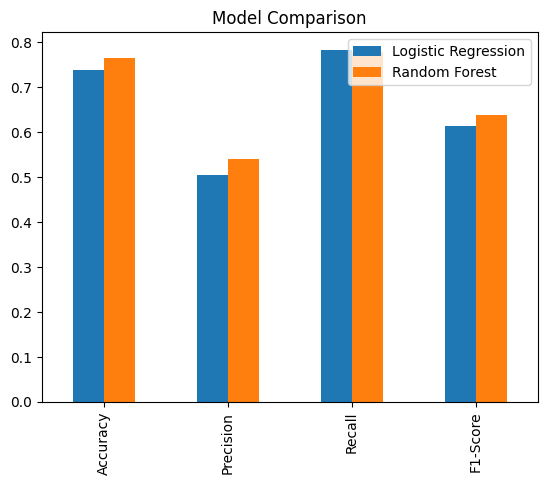

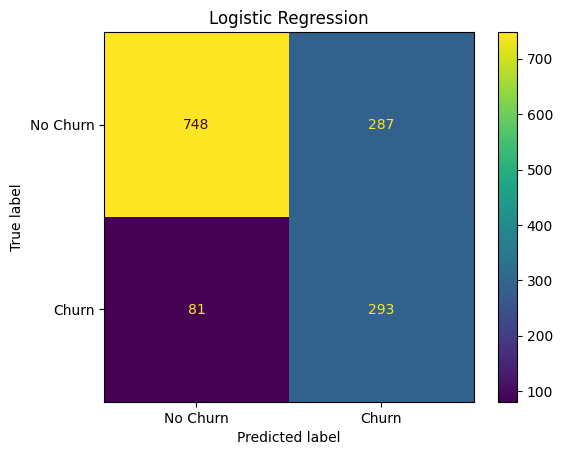

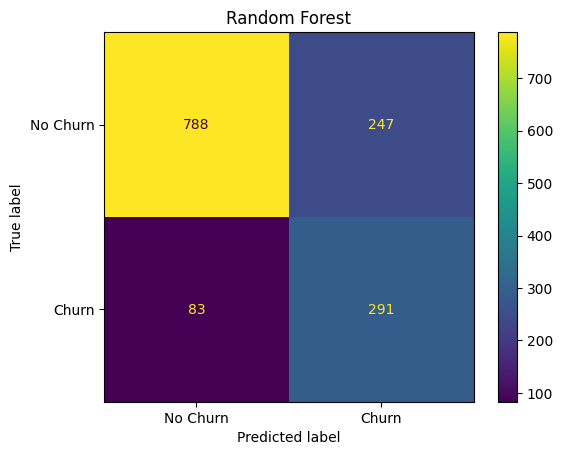

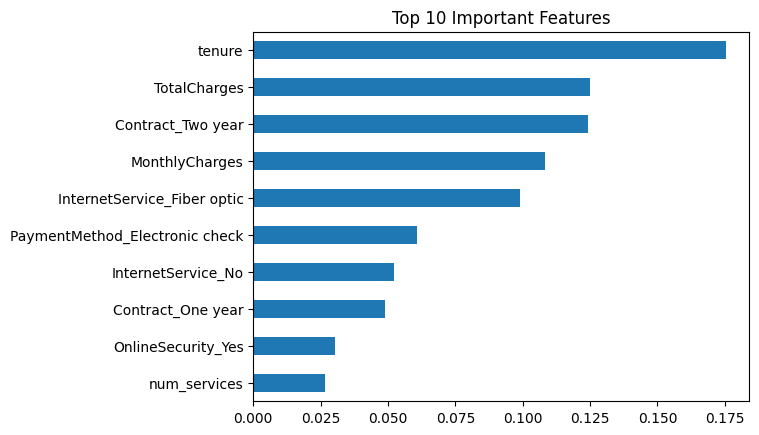

In [15]:
lr_pred = lr.predict(X_test)
rf_pred = rf.predict(X_test)
                                     #model evaluation
results = pd.DataFrame({
    "Logistic Regression": [accuracy_score(y_test, lr_pred), precision_score(y_test, lr_pred),
                            recall_score(y_test, lr_pred), f1_score(y_test, lr_pred)],
    "Random Forest": [accuracy_score(y_test, rf_pred), precision_score(y_test, rf_pred),
                      recall_score(y_test, rf_pred), f1_score(y_test, rf_pred)]
}, index=["Accuracy", "Precision", "Recall", "F1-Score"])
display(results.round(4))

results.plot(kind="bar")
plt.title("Model Comparison")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, lr_pred, display_labels=["No Churn", "Churn"])
plt.title("Logistic Regression")
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, display_labels=["No Churn", "Churn"])
plt.title("Random Forest")
plt.show()

importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values().tail(10).plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()

In [16]:
def predict_churn(customer):
    data = pd.concat([df.drop("Churn", axis=1), pd.DataFrame([customer])])
    new_X = make_features(data).tail(1)                                         #application/prediction
    new_X = scaler.transform(new_X)
    pred = rf.predict(new_X)[0]
    prob = rf.predict_proba(new_X)[0][1] * 100
    if pred == 1:
        print("Churn, probability:", round(prob, 2), "%")
    else:
        print("No Churn, probability:", round(prob, 2), "%")

customer_1 = {"gender": "Female", "SeniorCitizen": 1, "Partner": "No", "Dependents": "No",
              "tenure": 2, "PhoneService": "Yes", "MultipleLines": "No",
              "InternetService": "Fiber optic", "OnlineSecurity": "No", "OnlineBackup": "No",
              "DeviceProtection": "No", "TechSupport": "No", "StreamingTV": "Yes",
              "StreamingMovies": "No", "Contract": "Month-to-month", "PaperlessBilling": "Yes",
              "PaymentMethod": "Electronic check", "MonthlyCharges": 85.5, "TotalCharges": 171.0}

customer_2 = {"gender": "Male", "SeniorCitizen": 0, "Partner": "Yes", "Dependents": "Yes",
              "tenure": 60, "PhoneService": "Yes", "MultipleLines": "Yes",
              "InternetService": "DSL", "OnlineSecurity": "Yes", "OnlineBackup": "Yes",
              "DeviceProtection": "Yes", "TechSupport": "Yes", "StreamingTV": "No",
              "StreamingMovies": "No", "Contract": "Two year", "PaperlessBilling": "No",
              "PaymentMethod": "Bank transfer (automatic)", "MonthlyCharges": 65.0, "TotalCharges": 3900.0}

predict_churn(customer_1)
predict_churn(customer_2)

compare = pd.DataFrame({"Actual": y_test.values[:10], "Predicted": rf.predict(X_test[:10])})
display(compare)

Churn, probability: 86.73 %
No Churn, probability: 4.47 %


,Actual,Predicted
0,0,0
1,0,1
2,0,0
3,0,1
4,0,0
5,0,1
6,0,1
7,0,0
8,0,0
9,1,1
